# 08 · Channel contributions, adstock & saturation, response functions
**Team 2 – Marketing Mix Modelling** · uses the final model from notebook 07 (refit on all 36 months)

Outputs for the other teams:
| File | For | What it is |
|---|---|---|
| `models/mmm/final_mmm.json` | Optimisation, ROI | every fitted parameter |
| `src/mmm_response.py` | Optimisation | `ResponseModel` — revenue and marginal ROAS for any spend |
| `outputs/mmm/contributions_monthly.csv` / `_long.csv` | ROI, Dashboard | monthly revenue decomposition |
| `outputs/mmm/channel_summary.csv` | ROI, Dashboard, Report | contribution, ROAS, mROAS, carryover per channel |
| `outputs/mmm/roas_bootstrap.csv` | ROI, Report | ROAS uncertainty (90% intervals) |
| `outputs/mmm/response_curves.csv` | Dashboard, ROI | curves on a spend grid (diminishing returns) |
| `outputs/mmm/adstock_decay.csv` | Dashboard, Report | carryover profile by month |

**ROAS here = incremental *revenue* per LKR of spend.** The dataset has no margin or cost data, so profit ROI cannot be computed. A ROAS above 1 does not by itself mean the spend is profitable.


In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.mmm_core import *
from src import mmm_plot_style as ps; ps.apply()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG, TAB, MOD = ROOT/"reports/figures", ROOT/"outputs/mmm", ROOT/"models/mmm"
for d in (FIG, TAB, MOD): d.mkdir(parents=True, exist_ok=True)

# ---- Inputs from Team 1 (Data Engineering & EDA) ----
DATA_PATH = ROOT / "data" / "processed" / "mmm_analysis_ready.csv"
SPLIT = json.load(open(ROOT / "data" / "processed" / "split_info.json"))
TRAIN_END = SPLIT["train_end"]   # documented chronological split (train 2023-01..2025-06, test 2025-07..2025-12)
LAB = CHANNEL_LABELS
df = load_data(DATA_PATH)
train, test = df[df.month <= TRAIN_END].reset_index(drop=True), df[df.month > TRAIN_END].reset_index(drop=True)
print(f"{len(df)} months | train {train.month.min():%Y-%m} → {train.month.max():%Y-%m} ({len(train)}) | test {test.month.min():%Y-%m} → {test.month.max():%Y-%m} ({len(test)})")

36 months | train 2023-01 → 2025-06 (30) | test 2025-07 → 2025-12 (6)


In [2]:
from src.mmm_response import ResponseModel
mmm = MMM.from_json(MOD / "final_mmm.json")
rm = ResponseModel(MOD / "final_mmm.json")
P = json.load(open(MOD / "final_mmm.json"))
print("model:", P["model_name"], "| fit period:", P["fit_period"], "| controls:", mmm.controls)
pred = mmm.predict(df); print("full-period fit:", {k: round(v, 3) for k, v in metrics(df[TARGET], pred).items()})

model: M3a + price index | fit period: 2023-01 to 2025-12 | controls: ['promotion_discount_pct', 'seasonal_demand_index', 'competitor_pressure_index_0_100', 'economic_sentiment_index_0_100', 'average_price_index']
full-period fit: {'RMSE': 3971414.892, 'MAE': 3082122.051, 'MAPE_%': 3.757, 'R2': 0.722}


## 1. Revenue decomposition
`base` is the revenue expected with zero media and the external factors at their average level. Control contributions are deviations from average, so they move above and below zero.

In [3]:
contrib = mmm.contributions(df)
contrib.columns = ["base"] + [LAB.get(c, c) for c in contrib.columns[1:]]
contrib.insert(0, "month", df.month)
contrib["predicted_revenue"] = pred; contrib["actual_revenue"] = df[TARGET].values
contrib.to_csv(TAB / "contributions_monthly.csv", index=False)
ctrl_names = mmm.controls
long = contrib.melt(id_vars="month", value_vars=["base"] + [LAB[c] for c in CHANNELS] + ctrl_names, var_name="component", value_name="revenue_lkr")
long["component_type"] = np.select([long.component.eq("base"), long.component.isin(LAB.values())], ["base", "media"], "external factor")
long.merge(df[["month"] + CHANNELS].melt(id_vars="month", var_name="ch", value_name="spend_lkr").assign(component=lambda d: d.ch.map(LAB)).drop(columns="ch"),
           on=["month", "component"], how="left").to_csv(TAB / "contributions_long.csv", index=False)
contrib.head(3)

,month,base,TV,Facebook/Instagram,Google Search,YouTube,Radio,Outdoor,promotion_discount_pct,seasonal_demand_index,competitor_pressure_index_0_100,economic_sentiment_index_0_100,average_price_index,predicted_revenue,actual_revenue
0,2023-01-01,"38,886,029.088","4,265,565.798","2,948,281.954","12,226,117.573","8,721,645.298",0.000,"14,079,073.032","-1,521,846.521","723,994.486","-192,758.877","341,250.209","-1,106,765.608","79,370,586.432",68727157
1,2023-02-01,"38,886,029.088","4,170,741.136","3,404,756.655","13,129,936.571","9,311,324.103",0.000,"15,963,190.270","-755,309.733","-1,882,385.663","-310,517.027","408,936.201","-909,571.632","81,417,129.968",73594547
2,2023-03-01,"38,886,029.088","4,612,225.296","2,924,572.195","14,605,441.216","9,498,958.190",0.000,"15,295,065.021","-1,675,153.878","-1,013,592.280","118,459.092","502,004.440","-971,843.414","82,782,164.967",85063287


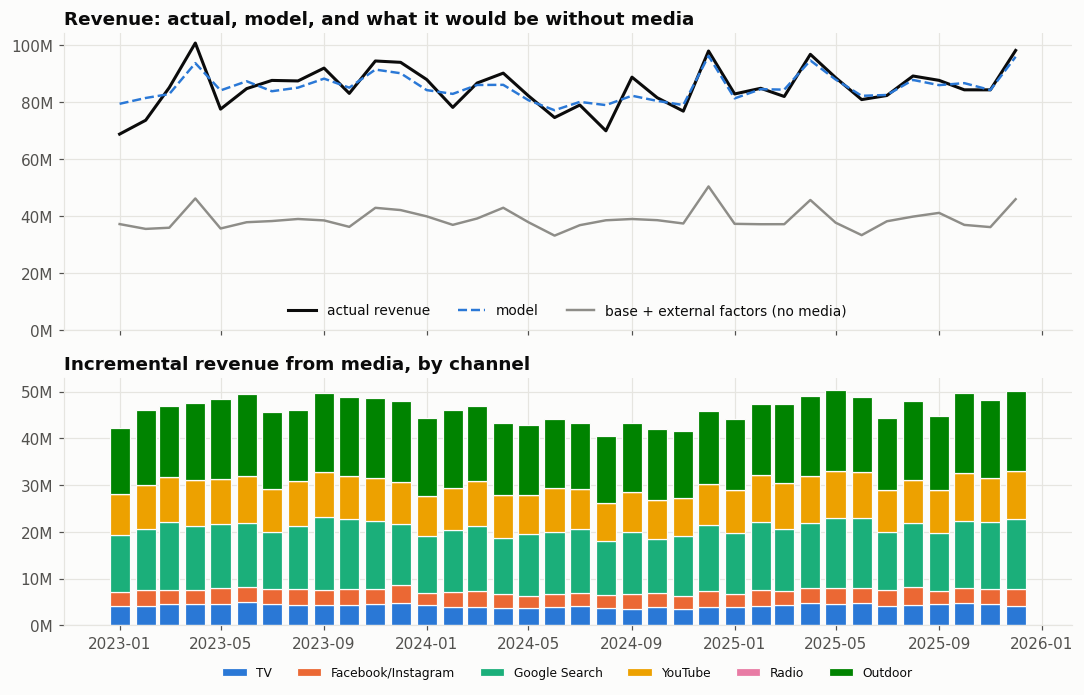

In [4]:
media = contrib[[LAB[c] for c in CHANNELS]]
fig, axs = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
ax = axs[0]
ax.plot(df.month, df[TARGET], color=ps.ACTUAL_COLOR, label="actual revenue")
ax.plot(df.month, pred, color=ps.PRED_COLOR, ls="--", lw=1.6, label="model")
ax.plot(df.month, contrib["base"] + contrib[ctrl_names].sum(1), color=ps.CONTROL_COLOR, lw=1.6, label="base + external factors (no media)")
ps.millions(ax); ax.set_ylim(0, None); ax.legend(loc="lower center", ncol=3, fontsize=9, bbox_to_anchor=(0.5, 0.0)); ax.set_title("Revenue: actual, model, and what it would be without media")
ax = axs[1]
bottom = np.zeros(len(df))
for col in media.columns:
    ax.bar(df.month, media[col], bottom=bottom, width=24, color=ps.CHANNEL_COLORS[col], label=col, edgecolor=ps.SURFACE, linewidth=0.8)
    bottom += media[col].values
ps.millions(ax); ax.set_title("Incremental revenue from media, by channel"); ax.legend(ncol=6, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout(); fig.savefig(FIG / "08_decomposition.png"); plt.show()

## 2. Channel contribution & ROAS summary

In [5]:
def channel_table(d, c):
    sp = d[CHANNELS].sum(); con = c[[LAB[x] for x in CHANNELS]].sum(); con.index = CHANNELS
    cur = pd.Series(P["current_monthly_spend"])
    t = pd.DataFrame({
        "total_spend_lkr": sp, "incremental_revenue_lkr": con,
        "spend_share_pct": sp / sp.sum() * 100, "contribution_share_pct": con / con.sum() * 100 if con.sum() > 0 else 0,
        "share_of_total_revenue_pct": con / d[TARGET].sum() * 100,
        "roas": con / sp,
        "current_monthly_spend_lkr": cur,
        "marginal_roas_at_current": [float(rm.marginal_roas(x, cur[x])) for x in CHANNELS],
        "adstock_lambda": pd.Series(mmm.lam), "carryover_half_life_months": [rm.carryover_half_life(x) for x in CHANNELS],
        "hill_K_x_mean_spend": pd.Series(mmm.K), "saturation_at_current_pct": [float(rm.response(x, cur[x]) / rm.beta[x] * 100) if rm.beta[x] > 0 else np.nan for x in CHANNELS],
    })
    t.index = [LAB[x] for x in CHANNELS]; t.index.name = "channel"
    return t
summary = channel_table(df, contrib)
summary["roas_rank"] = summary.roas.rank(ascending=False, method="min").astype(int)
summary.to_csv(TAB / "channel_summary.csv")
tot_media = summary.incremental_revenue_lkr.sum()
print(f"Media-driven revenue: {tot_media/1e6:,.1f}M LKR = {tot_media/df[TARGET].sum()*100:.1f}% of revenue | overall media ROAS {tot_media/df[CHANNELS].sum().sum():.2f}")
summary.drop(columns=["total_spend_lkr", "incremental_revenue_lkr", "current_monthly_spend_lkr"]).round(2)

Media-driven revenue: 1,663.4M LKR = 54.3% of revenue | overall media ROAS 2.49


,spend_share_pct,contribution_share_pct,share_of_total_revenue_pct,roas,marginal_roas_at_current,adstock_lambda,carryover_half_life_months,hill_K_x_mean_spend,saturation_at_current_pct,roas_rank
channel,,,,,,,,,,
TV,23.470,9.260,5.030,0.980,0.480,0.300,0.580,1.110,49.230,4
Facebook/Instagram,23.680,6.820,3.710,0.720,0.410,0.080,0.270,1.410,42.190,5
Google Search,17.850,29.280,15.900,4.080,1.270,0.000,0.080,0.520,67.540,3
YouTube,11.950,20.020,10.870,4.170,1.160,0.110,0.310,0.500,69.690,2
Radio,8.990,0.000,0.000,0.000,0.000,0.220,0.460,0.580,NaN,6
Outdoor,14.060,34.620,18.800,6.120,1.910,0.380,0.710,0.510,67.750,1


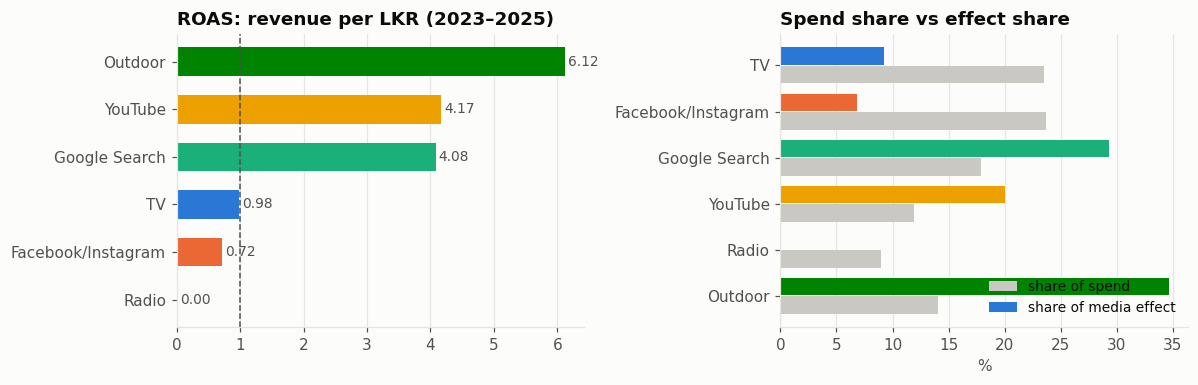

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
s = summary.sort_values("roas")
axs[0].barh(s.index, s.roas, color=[ps.CHANNEL_COLORS[i] for i in s.index], height=0.6)
for y, v in enumerate(s.roas): axs[0].text(v + 0.05, y, f"{v:.2f}", va="center", fontsize=9, color=ps.INK2)
axs[0].axvline(1, color=ps.INK2, lw=1, ls="--"); axs[0].set_title("ROAS: revenue per LKR (2023–2025)"); axs[0].grid(axis="y", visible=False)
y = np.arange(len(summary))
axs[1].barh(y + 0.2, summary.spend_share_pct, height=0.38, color="#c9c8c3", label="share of spend")
axs[1].barh(y - 0.2, summary.contribution_share_pct, height=0.38, color=[ps.CHANNEL_COLORS[i] for i in summary.index], label="share of media effect")
axs[1].set_yticks(y, summary.index); axs[1].invert_yaxis(); axs[1].set_xlabel("%"); axs[1].legend(loc="lower right", fontsize=9)
axs[1].set_title("Spend share vs effect share"); axs[1].grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG / "08_roas_and_shares.png"); plt.show()

## 3. Adstock (carryover) profiles
The share of one month's spend effect that is felt in that month and in each later month. A long tail means the channel keeps paying back after the spend stops.

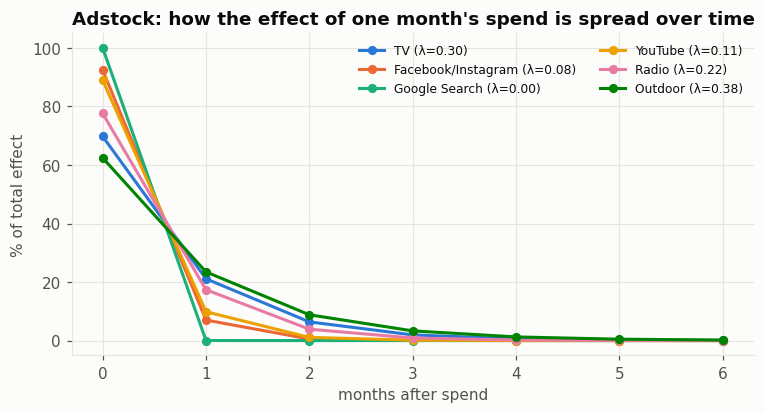

In [7]:
months = np.arange(7)
decay = pd.DataFrame({LAB[c]: adstock_weights(mmm.lam[c], len(months)) for c in CHANNELS}, index=months)
decay.rename_axis("months_after_spend").to_csv(TAB / "adstock_decay.csv")
fig, ax = plt.subplots(figsize=(8, 3.8))
for col in decay:
    ax.plot(months, decay[col] * 100, color=ps.CHANNEL_COLORS[col], marker="o", ms=5, label=f"{col} (λ={mmm.lam[[k for k,v in LAB.items() if v==col][0]]:.2f})")
ax.set_xlabel("months after spend"); ax.set_ylabel("% of total effect"); ax.legend(fontsize=8, ncol=2)
ax.set_title("Adstock: how the effect of one month's spend is spread over time")
fig.savefig(FIG / "08_adstock_decay.png"); plt.show()

## 4. Saturation / response curves (diminishing returns)
Each curve gives the incremental monthly revenue the channel generates at a sustained monthly spend level. The dot marks current spend (2025 monthly average). The dashed line is *marginal ROAS*: what the **next** LKR returns. Budget should move from channels with low marginal ROAS to channels with high marginal ROAS.

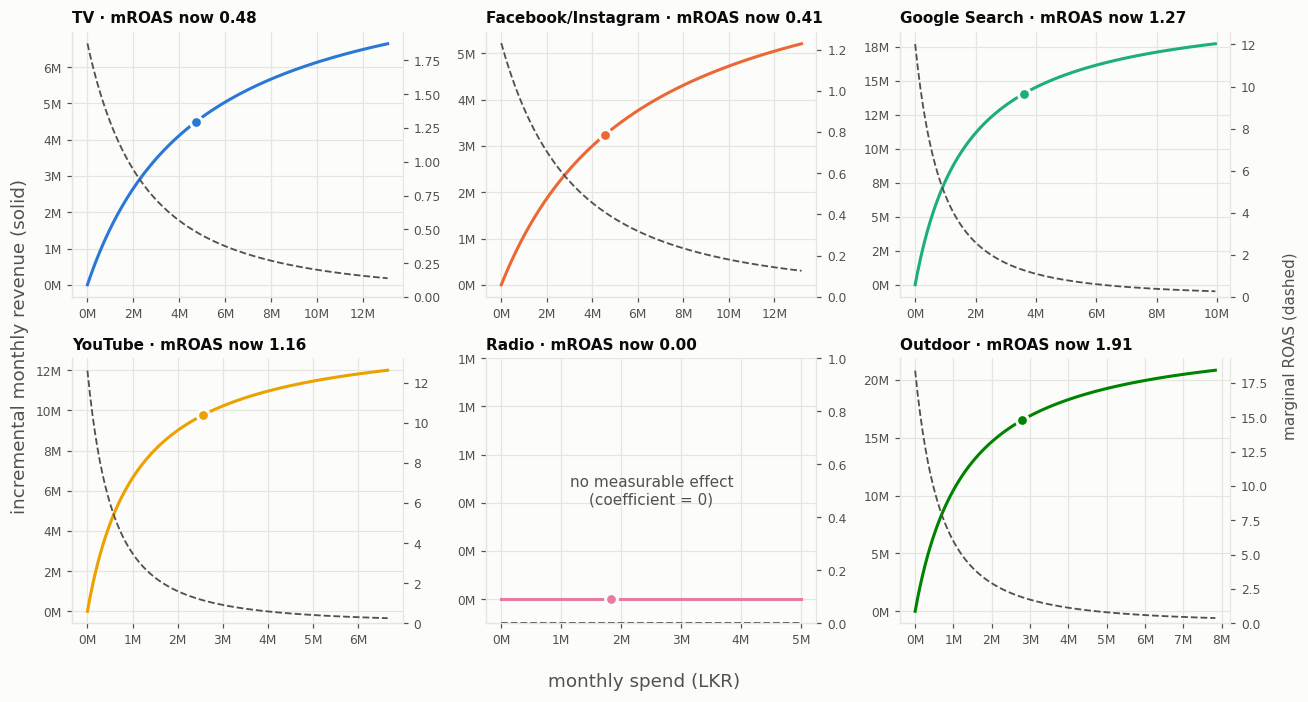

In [8]:
rows = []
for c in CHANNELS:
    grid = np.linspace(0, 3 * mmm.scale_[c], 121)
    rows.append(pd.DataFrame({"channel": LAB[c], "monthly_spend_lkr": grid, "incremental_revenue_lkr": rm.response(c, grid),
                              "marginal_roas": rm.marginal_roas(c, grid), "average_roas": rm.average_roas(c, grid),
                              "spend_vs_current": grid / P["current_monthly_spend"][c]}))
curves = pd.concat(rows); curves.to_csv(TAB / "response_curves.csv", index=False)

fig, axs = plt.subplots(2, 3, figsize=(12, 6.4))
for ax, c in zip(axs.flat, CHANNELS):
    d = curves[curves.channel == LAB[c]]; col = ps.CHANNEL_COLORS[LAB[c]]; cur = P["current_monthly_spend"][c]
    ax.plot(d.monthly_spend_lkr, d.incremental_revenue_lkr, color=col)
    ax.scatter([cur], [rm.response(c, cur)], s=60, color=col, edgecolor=ps.SURFACE, linewidth=2, zorder=3)
    ax2 = ax.twinx(); ax2.plot(d.monthly_spend_lkr, d.marginal_roas, color=ps.INK2, ls="--", lw=1.2); ax2.set_ylim(bottom=0)
    ax2.spines["right"].set_visible(True); ax2.grid(False); ax2.tick_params(labelsize=8)
    ps.millions(ax); ps.millions(ax, "x"); ax.tick_params(labelsize=8)
    ax.set_title(f"{LAB[c]} · mROAS now {float(rm.marginal_roas(c, cur)):.2f}", fontsize=10)
    if rm.beta[c] == 0:
        ax.set_ylim(-1e5, 1e6); ax2.set_ylim(0, 1); ax.text(0.5, 0.5, "no measurable effect\n(coefficient = 0)", transform=ax.transAxes, ha="center", va="center", color=ps.INK2)
fig.supxlabel("monthly spend (LKR)", color=ps.INK2); fig.supylabel("incremental monthly revenue (solid)", color=ps.INK2)
fig.text(0.995, 0.5, "marginal ROAS (dashed)", rotation=90, va="center", ha="right", color=ps.INK2)
fig.tight_layout(rect=(0, 0, 0.985, 1)); fig.savefig(FIG / "08_response_curves.png"); plt.show()

## 5. Reliability check 2: bootstrap uncertainty on ROAS
**Moving-block bootstrap** (blocks of 3 months, so autocorrelation is kept): resample the model residuals, rebuild a synthetic revenue series, refit the coefficients, and recompute ROAS. Repeat 1,000 times. The intervals show how far each channel's ROAS could move from noise alone. They are conditional on the chosen adstock/saturation settings, so the true uncertainty is somewhat larger.

In [9]:
rng = np.random.default_rng(42)
resid = df[TARGET].values - pred; n, B, L = len(df), 1000, 3
boot = []
for b in range(B):
    starts = rng.integers(0, n - L + 1, size=int(np.ceil(n / L)))
    e = np.concatenate([resid[s:s + L] for s in starts])[:n]
    db = df.copy(); db[TARGET] = pred + e
    mb = MMM(lam=mmm.lam, K=mmm.K, alpha=mmm.alpha, ridge=mmm.ridge, controls=mmm.controls).fit(db)
    cb = mb.contributions(db)[CHANNELS].sum()
    boot.append((cb / df[CHANNELS].sum()).values)
boot = pd.DataFrame(boot, columns=[LAB[c] for c in CHANNELS])
ci = pd.DataFrame({"roas_point": summary.roas, "roas_p05": boot.quantile(.05), "roas_median": boot.median(), "roas_p95": boot.quantile(.95),
                   "prob_roas_gt_1": (boot > 1).mean(), "prob_effect_zero": (boot < 1e-6).mean()})
ci.index.name = "channel"; ci.to_csv(TAB / "roas_bootstrap.csv")
ci.round(2)

,roas_point,roas_p05,roas_median,roas_p95,prob_roas_gt_1,prob_effect_zero
channel,,,,,,
TV,0.980,0.000,0.930,2.220,0.460,0.100
Facebook/Instagram,0.720,0.000,1.220,2.560,0.600,0.080
Google Search,4.080,0.150,2.460,4.780,0.850,0.030
YouTube,4.170,0.100,3.470,6.700,0.900,0.050
Radio,0.000,0.000,1.470,7.340,0.550,0.350
Outdoor,6.120,1.910,4.650,7.300,0.990,0.000


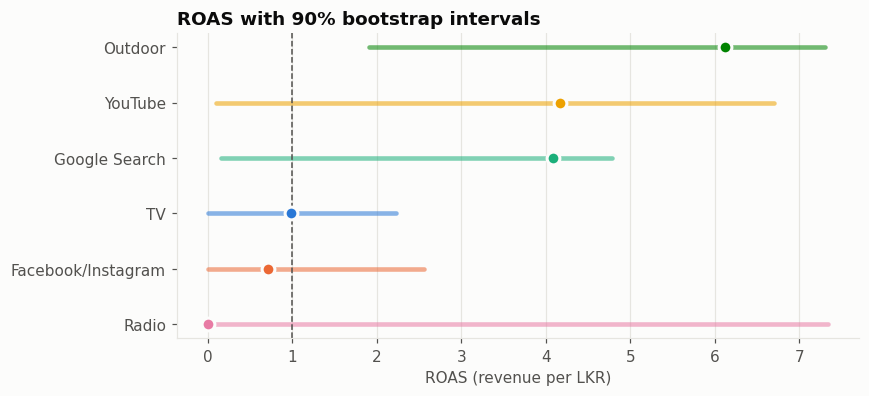

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.6))
c2 = ci.sort_values("roas_point")
for y, (name, r) in enumerate(c2.iterrows()):
    col = ps.CHANNEL_COLORS[name]
    ax.plot([r.roas_p05, r.roas_p95], [y, y], color=col, lw=3, solid_capstyle="round", alpha=.55)
    ax.scatter(r.roas_point, y, s=70, color=col, edgecolor=ps.SURFACE, linewidth=2, zorder=3)
ax.axvline(1, color=ps.INK2, ls="--", lw=1); ax.set_yticks(range(len(c2)), c2.index)
ax.set_xlabel("ROAS (revenue per LKR)"); ax.set_title("ROAS with 90% bootstrap intervals"); ax.grid(axis="y", visible=False)
fig.savefig(FIG / "08_roas_uncertainty.png"); plt.show()

## 6. Hand-off check: using the response functions
How the Budget Optimisation team will call the model. Below is a quick sanity check: revenue at current spend, and the effect of moving 10% of the total budget from the lowest to the highest marginal-ROAS channel.

In [11]:
cur = P["current_monthly_spend"]
base_rev = rm.total_revenue(cur)
mr = pd.Series({c: float(rm.marginal_roas(c, cur[c])) for c in CHANNELS})
lo, hi = mr.idxmin(), mr.idxmax(); shift = 0.10 * sum(cur.values())
shift = min(shift, cur[lo])
new = dict(cur); new[lo] -= shift; new[hi] += shift
print(f"Current total monthly budget: {sum(cur.values())/1e6:.2f}M LKR -> media-driven revenue {base_rev/1e6:.2f}M / month")
print(f"Move {shift/1e6:.2f}M from {LAB[lo]} (mROAS {mr[lo]:.2f}) to {LAB[hi]} (mROAS {mr[hi]:.2f}) -> {rm.total_revenue(new)/1e6:.2f}M / month "
      f"(+{(rm.total_revenue(new)-base_rev)/1e6:.2f}M, same budget)")
print("\nThis is only an illustration; the full constrained optimisation (min/max limits per channel) is Team 4's job.")

Current total monthly budget: 20.02M LKR -> media-driven revenue 48.03M / month
Move 1.83M from Radio (mROAS 0.00) to Outdoor (mROAS 1.91) -> 50.45M / month (+2.43M, same budget)

This is only an illustration; the full constrained optimisation (min/max limits per channel) is Team 4's job.
